# Wave-optics amplification in complete circular-lens and quadratic-field models

The point mass (PM), circular singular isothermal sphere (SIS), and spherical NFW cases are
compared in the image regimes that each model supports. The external-field examples keep
**convergence, shear, and two nonzero source coordinates**. They sample both two- and four-image
regions, and also the one-image region for SIS. These are full configurations of the quadratic
model, rather than an aligned-source slice.

In Einstein-radius units for the PM or SIS, the lens potential is
$$\psi(\mathbf x)=\psi_{\rm circular}(r)+\tfrac12\kappa r^2+
\tfrac12\gamma(x_1^2-x_2^2),\qquad
\psi_{\rm PM}=\ln r,\quad\psi_{\rm SIS}=r.$$
The axes are chosen along the shear eigenvectors, leaving the source
$\mathbf y=(y_1,y_2)$ unrestricted. The four independent dimensionless configuration parameters
are $(\kappa,\gamma,y_1,y_2)$. GLoW takes a scalar source distance, so its equivalent setup rotates
the source onto its first axis and sets
$\gamma_1'=\gamma\cos(2\varphi)$, $\gamma_2'=-\gamma\sin(2\varphi)$,
where $\varphi=\operatorname{atan2}(y_2,y_1)$. The helper code uses $(y_1,y_2)$ directly.

The complex amplification factor is
$$F(w,\mathbf y)=\frac{w}{2\pi i}\int d^2x\,
\exp\{iw[\tfrac12|\mathbf x-\mathbf y|^2-\psi(\mathbf x)-\phi_{\min}]\}.$$
The minimum-delay subtraction matches GLoW's phase convention. All methods are compared as
complex numbers, using $|F_{\rm method}-F_{\rm reference}|$. All timings use a single thread.

Primary references: [Takahashi & Nakamura (2003)](https://arxiv.org/abs/astro-ph/0305055),
[GLoW methods paper](https://arxiv.org/abs/2409.04606),
[FIONA paper](https://arxiv.org/abs/2603.12333), and
[Venumadhav's local source-operator paper](relative_binning_chang_refsdal_v5.pdf).

In [1]:
import os
for variable in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[variable] = '1'
os.environ.setdefault('MPLCONFIGDIR', '/tmp/test_glow_matplotlib')

from pathlib import Path
from math import comb, factorial
from statistics import median
from time import perf_counter
from importlib.metadata import version
import platform
import shutil
import numpy as np
import mpmath as mp
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from cycler import cycler
from IPython.display import display
from scipy.special import wofz, fresnel
from scipy.interpolate import CubicSpline, interp1d
from numpy.polynomial.legendre import leggauss
from glow import lenses, time_domain_c, freq_domain_c
from helper_functions import SLML, Ftilde_contour, ReconstructPeak, ampFac

my_colors = ['navy', 'coral', 'c', 'crimson', 'springgreen', 'gold',
             'dodgerblue', 'hotpink', 'forestgreen', 'moccasin', 'darkred', 'teal']
tex_ready = (shutil.which('latex') and shutil.which('dvipng') and shutil.which('kpsewhich')
             and os.popen('kpsewhich txfonts.sty').read().strip())
rc_params = {'axes.labelsize': 14, 'axes.titlesize': 14, 'legend.fontsize': 11,
             'xtick.labelsize': 12, 'ytick.labelsize': 12,
             'text.usetex': bool(tex_ready), 'text.latex.preamble': r'\usepackage{txfonts}',
             'font.size': 14, 'font.family': 'serif', 'font.serif': 'times',
             'mathtext.default': 'sf', 'lines.markeredgewidth': 1,
             'lines.linewidth': 2, 'axes.prop_cycle': cycler(color=my_colors)}
rcParams.update(rc_params)
if not tex_ready:
    rcParams['font.serif'] = ['DejaVu Serif']
    print('Install LaTeX, dvipng, and txfonts separately to enable the requested LaTeX plot labels.')
print(f"GLoW {version('glow')}; NumPy {version('numpy')}; SciPy {version('scipy')}")

Install LaTeX, dvipng, and txfonts separately to enable the requested LaTeX plot labels.
GLoW 0.1; NumPy 1.26.4; SciPy 1.15.2


## Independent and semi-analytic expressions

For an isolated PM, the exact hypergeometric expression is Eq. 17 of
[Takahashi & Nakamura](https://arxiv.org/abs/astro-ph/0305055). The implementation below uses
40-digit `mpmath`, independently of GLoW's optimized C routine.

For an SIS in a general quadratic external field, put
$A(\theta)=1-\kappa-\gamma\cos2\theta$ and
$B(\theta)=1+y_1\cos\theta+y_2\sin\theta$. Its **radial** diffraction integral is analytic:
$$I(\theta)=\int_0^\infty r e^{iw[A r^2/2-B r]}dr
=\frac{B}{A}J+\frac{i}{wA},$$
$$J=\sqrt{\frac{\pi}{2wA}}e^{i\pi/4}
\operatorname{wofz}\!\left(e^{5\pi i/4}B\sqrt{\frac{w}{2A}}\right).$$
Only a one-dimensional angular integral remains. The numerical quadrature below uses 512
Gauss–Legendre angles. This extends the radial-first calculation in
[GLoW, Eq. 65](https://arxiv.org/abs/2409.04606) to nonzero convergence and oblique shear.

For the PM in the full quadratic field, the source-derivative series implements
[Venumadhav, Eqs. 9, 14, C2–C3](relative_binning_chang_refsdal_v5.pdf). In principal shear
coordinates, $D=\partial_{y_1}^2-\partial_{y_2}^2$, and
$$G_\gamma=\sum_{n=0}^\infty\frac1{n!}
\left(\frac{i\gamma}{2w}\right)^nD^nG_{\rm PM}.$$
The code expands $D^n$ for arbitrary $(y_1,y_2)$, evaluates the radial derivatives by
hypergeometric functions, and applies the exact convergence rescaling. It stops after four
successive terms are below $2\times10^{-12}$ of the partial sum. This series assumes the
positive-parity macro field $1-\kappa>\gamma\geq0$.

The full SIS plus quadratic-field amplification is **not** evaluated by a closed formula here. The angular integral remains numerical. An analytic series for the *isolated* SIS is given by [Matsunaga and Yamamoto (2006)](https://arxiv.org/abs/astro-ph/0601701); that is a different calculation from the full-field angular quadrature used below.


In [2]:
def point_mass_formula(w, y):
    """Takahashi & Nakamura (2003), Eq. 17: https://arxiv.org/abs/astro-ph/0305055."""
    x_min = (y + np.sqrt(y*y + 4))/2
    phi_min = (x_min-y)**2/2 - np.log(x_min)
    result = []
    with mp.workdps(40):
        for frequency in np.atleast_1d(w):
            u = mp.mpf(str(frequency))/2
            prefactor = mp.exp(mp.pi*u/2 + 1j*u*(mp.log(u)-2*phi_min))
            result.append(complex(prefactor*mp.gamma(1-1j*u)
                                  *mp.hyp1f1(1j*u, 1, 1j*u*y*y)))
    return np.array(result)

def one_axis_weights(power, position):
    """Weights for d^(2*power)/dx^(2*power) G(x*x+other_coordinate_squared)."""
    return {
        k: mp.mpf(factorial(2*power)) * (2*position)**(2*k-2*power)
           / (factorial(2*power-k)*factorial(2*k-2*power))
        for k in range(power, 2*power+1)
    }


def shear_operator_weights(order, y1, y2):
    """Coefficients of (d11-d22)^order G(|y|^2), with arbitrary source angle.

    Expand (d11-d22)^n by the binomial theorem, then use the chain rule
    for each even Cartesian derivative. This is the general 2D form of
    Venumadhav's Appendix C source operator: relative_binning_chang_refsdal_v5.pdf.
    """
    weights = {}
    for q in range(order+1):
        x_weights = one_axis_weights(order-q, y1)
        y_weights = one_axis_weights(q, y2)
        factor = (-1)**q * comb(order, q)
        for k, x_value in x_weights.items():
            for l, y_value in y_weights.items():
                r = k+l
                weights[r] = weights.get(r, mp.mpf('0')) + factor*x_value*y_value
    return [(r, value) for r, value in weights.items() if value]


def point_mass_minimum(y1, y2, kappa, gamma):
    """Find all real positive u=1/r^2 roots of the exact quartic lens equation."""
    a, b = 1-kappa-gamma, 1-kappa+gamma
    u = np.poly1d([1., 0.])
    p = u*(y1*y1*(b-u)**2+y2*y2*(a-u)**2) - (a-u)**2*(b-u)**2
    images = []
    for root in p.r:
        if abs(root.imag)>1e-7 or root.real<=0:
            continue
        v = root.real
        x1, x2 = y1/(a-v), y2/(b-v)
        if abs(v*(x1*x1+x2*x2)-1)>1e-6:
            continue
        delay = (x1-y1)**2/2+(x2-y2)**2/2-np.log(np.hypot(x1,x2))
        delay -= kappa*(x1*x1+x2*x2)/2+gamma*(x1*x1-x2*x2)/2
        images.append((x1,x2,delay))
    return min(item[2] for item in images), images


class FullPMSeries:
    """Venumadhav's source-derivative series for the full positive-parity PM model.

    Implements Eqs. (9), (C2), (C3), and the exact convergence rescaling
    in Eq. (14) of relative_binning_chang_refsdal_v5.pdf. Shear is in its
    principal axes, while (y1,y2) is unrestricted. The minimum delay comes
    from the real roots of the exact quartic point-mass lens equation.
    """
    def __init__(self, y1, y2, kappa, gamma, max_order=30, tolerance=2e-12, digits=50):
        self.digits, self.tolerance = digits, tolerance
        self.kappa, self.gamma = kappa, gamma
        self.y1, self.y2 = y1, y2
        self.phi_min, self.images = point_mass_minimum(y1,y2,kappa,gamma)
        lam=1-kappa
        self.y1_reduced, self.y2_reduced = mp.mpf(str(y1/np.sqrt(lam))), mp.mpf(str(y2/np.sqrt(lam)))
        self.gamma_reduced=mp.mpf(str(gamma/lam))
        with mp.workdps(digits):
            self.weights=[shear_operator_weights(n,self.y1_reduced,self.y2_reduced)
                          for n in range(max_order+1)]

    def one_frequency(self, frequency):
        with mp.workdps(self.digits):
            w=mp.mpf(str(frequency))
            s=self.y1_reduced**2+self.y2_reduced**2
            a=1-1j*w/2
            z=-1j*w*s/2
            prefactor=mp.exp(mp.pi*w/4+1j*w*mp.log(w/2)/2)*mp.gamma(a)
            derivatives=[]
            total=mp.mpc(0)
            small=0
            for n, weights in enumerate(self.weights):
                term=mp.mpc(0)
                for r,weight in weights:
                    while len(derivatives)<=r:
                        k=len(derivatives)
                        derivatives.append((-1j*w/2)**k*mp.rf(a,k)/mp.factorial(k)
                                           *mp.hyp1f1(a+k,1+k,z))
                    term+=weight*derivatives[r]
                term*=(1j*self.gamma_reduced/(2*w))**n/mp.factorial(n)
                total+=term
                if n and abs(term)<self.tolerance*abs(total): small+=1
                else: small=0
                if small==4: break
            if small<4: raise RuntimeError(f'Series did not converge at w={frequency}, n={n}')
            lam=mp.mpf(str(1-self.kappa))
            phase=mp.exp(1j*w*(mp.mpf(str(self.y1*self.y1+self.y2*self.y2))/2
                                   -mp.mpf(str(self.phi_min)) + mp.log(lam)/2))
            return complex(phase*prefactor*total/lam),n

    def __call__(self, frequencies):
        result=[self.one_frequency(w) for w in np.atleast_1d(frequencies)]
        self.orders=[x[1] for x in result]
        return np.array([x[0] for x in result])



def sis_minimum(y1,y2,kappa,gamma):
    """Stationary points of a circular SIS in principal shear coordinates."""
    a,b=1-kappa-gamma,1-kappa+gamma
    u=np.poly1d([1.,0.])
    p=u*u*(y1*y1*(b-u)**2+y2*y2*(a-u)**2)-(a-u)**2*(b-u)**2
    images=[]
    for root in p.r:
        if abs(root.imag)>1e-7 or root.real<=0: continue
        v=root.real
        x1,x2=y1/(a-v),y2/(b-v)
        if abs(v*np.hypot(x1,x2)-1)>1e-6: continue
        r=np.hypot(x1,x2)
        t=.5*((x1-y1)**2+(x2-y2)**2)-r
        t-=kappa*r*r/2+gamma*(x1*x1-x2*x2)/2
        images.append((x1,x2,t))
    return min(im[2] for im in images),images


class SISAngular:
    """Full circular SIS plus quadratic field: analytic radial integral, numeric angular integral.

    For A(theta)=1-kappa-gamma*cos(2*theta) and
    B(theta)=1+y1*cos(theta)+y2*sin(theta), the radial integral is
    I=integral_0^infinity r*exp[i*w*(A*r*r/2-B*r)] dr = (B/A)*J+i/(w*A),
    where J=sqrt(pi/(2*w*A))*exp(i*pi/4)*wofz(exp(5*i*pi/4)*B*sqrt(w/(2*A))).
    This generalizes the radial integration in Eq. 65 of GLoW:
    https://arxiv.org/abs/2409.04606. It assumes 1-kappa>gamma>=0.
    """
    def __init__(self,y1,y2,kappa=0,gamma=0,n_angle=512):
        nodes,weights=leggauss(n_angle)
        theta=np.pi*(nodes+1)
        self.weights=np.pi*weights
        self.a=1-kappa-gamma*np.cos(2*theta)
        self.b=1+y1*np.cos(theta)+y2*np.sin(theta)
        self.y_squared=y1*y1+y2*y2
        self.phi_min,self.images=sis_minimum(y1,y2,kappa,gamma)

    def __call__(self,w):
        answer=[]
        for wi in np.atleast_1d(w):
            z=np.exp(5j*np.pi/4)*self.b*np.sqrt(wi/(2*self.a))
            j=np.sqrt(np.pi/(2*wi*self.a))*np.exp(1j*np.pi/4)*wofz(z)
            radial=(self.b/self.a)*j+1j/(wi*self.a)
            unshifted=wi/(2j*np.pi)*np.dot(self.weights,radial)
            answer.append(unshifted*np.exp(1j*wi*(self.y_squared/2-self.phi_min)))
        return np.array(answer)


def sis_angular_formula(w,y1,y2,kappa=0,gamma=0,n_angle=512):
    method=SISAngular(y1,y2,kappa,gamma,n_angle)
    return method(w),method.images


def sis_old(w,y,n_angle=512):
    nodes,weights=leggauss(n_angle)
    theta=np.pi*(nodes+1)/2
    phi_min=-y-.5
    answer=[]
    for wi in np.atleast_1d(w):
        alpha=np.sqrt(wi/np.pi)*(1+y*np.cos(theta))
        s,c=fresnel(alpha)
        integrand=alpha*np.exp(-.5j*np.pi*alpha**2)*((1+1j)/2+c+1j*s)
        answer.append(np.exp(1j*wi*(y*y/2-phi_min))*(1-1j*np.pi/2*np.dot(weights,integrand)))
    return np.array(answer)




## Lens configurations and GLoW coordinate rotation

For the external-field cases, $\kappa$ and $\gamma$ are both nonzero and both source coordinates
are nonzero. The PM has two or four ordinary images. A circular SIS can have one, two, or four
ordinary images in this field; the central SIS cusp is not counted as an ordinary image. The
spherical NFW examples have one or three images. None of the examples sits exactly on a caustic.
The NFW profile uses $\psi_0=2$ and $x_s=1$ in GLoW's dimensionless convention.

In [3]:
CASES = [
    dict(id='PM', model='PM', regime='2 images', y1=.3, y2=0., kappa=0., gamma=0.),
    dict(id='PM + field: 2', model='PM + field', regime='2 images', y1=.55, y2=.07, kappa=.1, gamma=.1),
    dict(id='PM + field: 4', model='PM + field', regime='4 images', y1=.04, y2=.04, kappa=.1, gamma=.1),
    dict(id='SIS: 1', model='SIS', regime='1 image', y1=1.5, y2=0., kappa=0., gamma=0.),
    dict(id='SIS: 2', model='SIS', regime='2 images', y1=.3, y2=0., kappa=0., gamma=0.),
    dict(id='SIS + field: 1', model='SIS + field', regime='1 image', y1=2., y2=.2, kappa=.1, gamma=.2),
    dict(id='SIS + field: 2', model='SIS + field', regime='2 images', y1=.6, y2=.12, kappa=.1, gamma=.2),
    dict(id='SIS + field: 4', model='SIS + field', regime='4 images', y1=.04, y2=.06, kappa=.1, gamma=.2),
    dict(id='NFW: 1', model='NFW', regime='1 image', y1=.3, y2=0., kappa=0., gamma=0.),
    dict(id='NFW: 3', model='NFW', regime='3 images', y1=.1, y2=0., kappa=0., gamma=0.),
]
CASE_BY_ID = {case['id']: case for case in CASES}
W = np.geomspace(.1, 20, 80)

def make_glow_lens(case):
    """Rotate the source onto GLoW's x1 axis without restricting relative orientation."""
    if case['model'].startswith('PM'):
        circular = lenses.Psi_PointLens({'psi0': 1})
    elif case['model'].startswith('SIS'):
        circular = lenses.Psi_SIS({'psi0': 1})
    else:
        return lenses.Psi_NFW({'psi0': 2, 'xs': 1})
    if case['gamma'] == 0 and case['kappa'] == 0:
        return circular
    phi = np.arctan2(case['y2'], case['y1'])
    field = lenses.Psi_Ext({'kappa': case['kappa'],
                           'gamma1': case['gamma']*np.cos(2*phi),
                           'gamma2': -case['gamma']*np.sin(2*phi)})
    return lenses.CombinedLens({'lenses': [circular, field]})

def glow_numerical(case, nt=5000):
    """GLoW time response followed by the regularized FFT, on one thread."""
    lens = make_glow_lens(case)
    y = np.hypot(case['y1'], case['y2'])
    method = time_domain_c.It_SingleIntegral_C if lens.isAxisym else time_domain_c.It_MultiContour_C
    response = method(lens, y, {'Nt': nt, 'tmax': 1000, 'parallel': False})
    amplification = freq_domain_c.Fw_FFT_C(
        response, {'wmin': .1, 'wmax': 20, 'parallel': False,
                   'eval_mode': 'exact', 'N_above_discard': 7})
    return response, amplification

def ordinary_image_count(response):
    return sum(point['type'] in ('min', 'saddle', 'max') for point in response.p_crits)

display(pd.DataFrame(CASES).set_index('id'))

,model,regime,y1,y2,kappa,gamma
id,,,,,,
PM,PM,2 images,0.30,0.00,0.0,0.0
PM + field: 2,PM + field,2 images,0.55,0.07,0.1,0.1
PM + field: 4,PM + field,4 images,0.04,0.04,0.1,0.1
SIS: 1,SIS,1 image,1.50,0.00,0.0,0.0
SIS: 2,SIS,2 images,0.30,0.00,0.0,0.0
SIS + field: 1,SIS + field,1 image,2.00,0.20,0.1,0.2
SIS + field: 2,SIS + field,2 images,0.60,0.12,0.1,0.2
SIS + field: 4,SIS + field,4 images,0.04,0.06,0.1,0.2
NFW: 1,NFW,1 image,0.30,0.00,0.0,0.0


## Prepare the independent and GLoW calculations

The comparison grid has 80 logarithmically spaced frequencies, $0.1\leq w\leq20$.
For NFW, which has no formula here, a 20,000-point GLoW time grid is a numerical
convergence comparison rather than an exact reference. For external-field cases the
5,000-point FFT is compared with the independent PM series or SIS semi-analytic angular integral; the
two four-image examples also receive a 20,000-point GLoW check.

In [4]:
references = {}
reference_methods = {}
glow_methods = {}
values = {}
image_counts = {}
for case in CASES:
    name = case['id']
    y = np.hypot(case['y1'], case['y2'])
    if case['model'] == 'PM':
        references[name] = point_mass_formula(W, y)
        reference_methods[name] = 'PM exact formula'
    elif case['model'] == 'PM + field':
        method = FullPMSeries(case['y1'], case['y2'], case['kappa'], case['gamma'],
                              max_order=50, digits=70)
        references[name] = method(W)
        reference_methods[name] = 'PM source series'
    elif case['model'].startswith('SIS'):
        method = SISAngular(case['y1'], case['y2'], case['kappa'], case['gamma'])
        references[name] = method(W)
        reference_methods[name] = 'SIS semi-analytic integral'
    response, method = glow_numerical(case)
    glow_methods[name] = method
    image_counts[name] = ordinary_image_count(response)
    values[name] = {'GLoW FFT': method(W)}
    if case['model'] == 'PM':
        values[name]['GLoW dedicated'] = freq_domain_c.Fw_AnalyticPointLens_C(
            y, {'parallel': False})(W)
    elif case['model'] == 'SIS':
        values[name]['GLoW dedicated'] = freq_domain_c.Fw_SemiAnalyticSIS_C(
            y, {'parallel': False})(W)
    if case['regime'] == '4 images' or case['model'] == 'NFW':
        _, finer = glow_numerical(case, nt=20000)
        values[name]['GLoW FFT, 20k'] = finer(W)
    print(name, 'ordinary images:', image_counts[name],
          'finite GLoW values:', int(np.isfinite(values[name]['GLoW FFT']).sum()), '/', len(W))
    assert image_counts[name] == int(case['regime'].split()[0])

PM ordinary images: 2 finite GLoW values: 80 / 80


PM + field: 2 ordinary images: 2 finite GLoW values: 80 / 80


PM + field: 4 ordinary images: 4 finite GLoW values: 80 / 80
SIS: 1 ordinary images: 1 finite GLoW values: 80 / 80
SIS: 2 ordinary images: 2 finite GLoW values: 80 / 80


SIS + field: 1 ordinary images: 1 finite GLoW values: 80 / 80


SIS + field: 2 ordinary images: 2 finite GLoW values: 80 / 80


SIS + field: 4 ordinary images: 4 finite GLoW values: 80 / 80
NFW: 1 ordinary images: 1 finite GLoW values: 80 / 80


NFW: 3 ordinary images: 3 finite GLoW values: 80 / 80


## Local contour calculation for every PM case

[`helper_functions.py`](helper_functions.py) accepts arbitrary $(y_1,y_2,\kappa,\gamma_1,\gamma_2)$
for a point mass. Its `SLML` class finds images, `Ftilde_contour` sums time-delay contours,
`ReconstructPeak` repairs saddle peaks, and `ampFac` Fourier transforms the response.
The calculation below uses $t_{\max}=100$, contour spacing
$\Delta t=\pi/(20\times3)$, lens-plane spacing $\Delta x_1=\Delta x_2=0.06$,
and 32,768 uniform time samples. Both raw and repaired responses use the same contour work.
The singular saddle contribution follows
[Ulmer & Goodman (1995)](https://ui.adsabs.harvard.edu/abs/1995ApJ...442...67U/abstract).

In [5]:
HELPER_T_MAX = 100
HELPER_DT = np.pi/(20*3)
HELPER_DX = .06
HELPER_N_TIME = 32768

def make_helper_lens(case):
    return SLML(k=case['kappa'], g1=case['gamma'], g2=0., mratio=1.,
                y1=case['y1'], y2=case['y2'])

def prepare_helper_amplification(case):
    """Compute the shared contour response and both raw/repaired FFT interpolants."""
    lens = make_helper_lens(case)
    delays, response = Ftilde_contour(
        lens, HELPER_T_MAX, HELPER_DT, dx1=HELPER_DX, dx2=HELPER_DX)
    uniform_time = np.linspace(0, HELPER_T_MAX, HELPER_N_TIME)
    raw = interp1d(delays, response, fill_value='extrapolate')(uniform_time)
    repaired = ReconstructPeak(lens, uniform_time, raw).get_peak_reconstructed_Ft()
    prepared = {}
    for label, time_response in [('raw', raw), ('peak repair', repaired)]:
        frequency, amplification = ampFac(uniform_time, time_response)
        band = frequency < 30
        prepared[label] = CubicSpline(frequency[band], amplification[band])
    return prepared

helper_prepared = {}
for case in CASES:
    if not case['model'].startswith('PM'):
        continue
    name = case['id']
    helper_prepared[name] = prepare_helper_amplification(case)
    values[name]['Helper raw'] = helper_prepared[name]['raw'](W)
    values[name]['Helper peak repair'] = helper_prepared[name]['peak repair'](W)
    print(name, 'helper images:', len(make_helper_lens(case).img))

PM helper images: 2


PM + field: 2 helper images: 2


PM + field: 4 helper images: 4


## Independent checks of the series and angular expression

The PM source series is checked against a direct, independently integrated lens-plane
diffraction integral after rotating its radial contour by $\pi/4$. This is a sparse and
expensive validation, not the series used for the full frequency grid. The isolated PM
zero-shear limit and the isolated SIS radial formula are also checked.

In [6]:
def point_mass_contour_check(w, case, n_angle=48):
    """Direct rotated-contour integral of the full PM potential, independent of the series."""
    y1, y2 = case['y1'], case['y2']
    kappa, gamma = case['kappa'], case['gamma']
    phi_min, _ = point_mass_minimum(y1, y2, kappa, gamma)
    nodes, weights = leggauss(n_angle)
    angles = np.pi*(nodes+1)
    weights = weights/2
    with mp.workdps(30):
        frequency = mp.mpf(str(w))
        integral = mp.mpc(0)
        for angle, weight in zip(angles, weights):
            a = mp.mpf(str(1-kappa-gamma*np.cos(2*angle)))
            b = mp.mpf(str(y1*np.cos(angle)+y2*np.sin(angle)))
            def radial(u):
                radius = mp.exp(1j*mp.pi/4)*mp.sqrt(2*u/frequency)
                return mp.exp(-a*u-1j*frequency*b*radius-1j*frequency*mp.log(radius))
            integral += mp.mpf(str(weight))*mp.quad(radial, [0, 1, 5, 20, 80])
        return complex(integral*mp.exp(1j*frequency*((y1*y1+y2*y2)/2-phi_min)))

series_checks = []
for case_name, frequencies in [('PM + field: 2', [1.]), ('PM + field: 4', [1., 5.])]:
    case = CASE_BY_ID[case_name]
    series = FullPMSeries(case['y1'], case['y2'], case['kappa'], case['gamma'],
                          max_order=50, digits=70)
    for w in frequencies:
        error = abs(series([w])[0]-point_mass_contour_check(w, case))
        series_checks.append({'case': case_name, 'w': w, 'complex error': error})
zero_shear = FullPMSeries(.24, .18, 0., 0.)([.1, 1., 10.])
zero_shear_error = max(abs(zero_shear-point_mass_formula([.1, 1., 10.], .3)))
sis_radial_error = max(abs(sis_angular_formula([.1, 1., 10.], .3, 0.)[0]
                           -sis_old([.1, 1., 10.], .3)))
display(pd.DataFrame(series_checks))
print('Zero-shear PM series vs exact PM formula:', zero_shear_error)
print('General SIS angular integral vs isolated SIS Eq. 65 form:', sis_radial_error)
assert max(row['complex error'] for row in series_checks) < 1e-9
assert zero_shear_error < 1e-11 and sis_radial_error < 1e-10

,case,w,complex error
0,PM + field: 2,1.0,7.067763e-15
1,PM + field: 4,1.0,1.460270e-15
2,PM + field: 4,5.0,8.263521e-15


Zero-shear PM series vs exact PM formula: 2.0471501066083613e-15
General SIS angular integral vs isolated SIS Eq. 65 form: 1.4654943925052066e-14


## Complex residual against the selected reference

The selected reference for each single-configuration comparison follows the same priority as
the 10-choice benchmark: independent PM formula or SIS semi-analytic integral, repaired helper,
GLoW 20k, raw helper, GLoW dedicated, GLoW 5k, then PM series. Thus the PM plus field rows use
the repaired helper. This is a comparison convention, not an independent accuracy guarantee.
Absolute complex differences remain meaningful near destructive-interference zeros.


In [6]:
def case_curves(name):
    """Return every computed F(w), including the independent expression when available."""
    curves = dict(values[name])
    if name in references:
        curves[reference_methods[name]] = references[name]
    return curves


def choose_case_reference(curves):
    """Use the repaired helper before GLoW for PM plus field."""
    order = ('PM exact formula', 'SIS semi-analytic integral', 'Helper peak repair',
             'GLoW FFT, 20k', 'Helper raw', 'GLoW dedicated', 'GLoW FFT',
             'PM source series')
    return next(name for name in order if name in curves and np.isfinite(curves[name]).all())


accuracy_rows = []
for case in CASES:
    name = case['id']
    curves = case_curves(name)
    best_name = choose_case_reference(curves)
    best = curves[best_name]
    for method_name, result in curves.items():
        finite = np.isfinite(result)
        error = abs(result[finite]-best[finite]) if finite.any() else np.array([np.nan])
        accuracy_rows.append({'case': name, 'images': image_counts[name], 'method': method_name,
                              'reference': best_name, 'finite': f'{finite.sum()}/{len(W)}',
                              'median error': np.median(error), 'maximum error': np.max(error)})
accuracy = pd.DataFrame(accuracy_rows)
display(accuracy)


,case,images,method,reference,finite,median error,maximum error
0,PM,2,GLoW FFT,PM exact formula,80/80,7.301871e-06,6.546455e-05
1,PM,2,GLoW dedicated,PM exact formula,80/80,3.267231e-10,2.427769e-06
2,PM,2,Helper raw,PM exact formula,80/80,6.656528e-03,9.522738e-02
3,PM,2,Helper peak repair,PM exact formula,80/80,1.024207e-03,2.816588e-02
4,PM,2,PM exact formula,PM exact formula,80/80,0.000000e+00,0.000000e+00
5,PM + field: 2,2,GLoW FFT,Helper peak repair,80/80,1.063494e-03,1.752344e-02
6,PM + field: 2,2,Helper raw,Helper peak repair,80/80,7.853224e-03,1.114050e-01
7,PM + field: 2,2,Helper peak repair,Helper peak repair,80/80,0.000000e+00,0.000000e+00
8,PM + field: 2,2,PM source series,Helper peak repair,80/80,1.178206e-03,1.525454e-02
9,PM + field: 4,4,GLoW FFT,Helper peak repair,80/80,4.200102e-02,3.329818e-01


## Single-configuration amplification and residual curves

Each row uses the same 80-frequency values as before. The panels show amplitude, unwrapped
phase, and absolute complex residual against the selected reference. In both PM plus field
rows, the repaired helper (`helper_corrected`) is the reference; the independent PM series
remains visible as a separate curve. The 10-choice, 1,024-frequency comparison follows below.


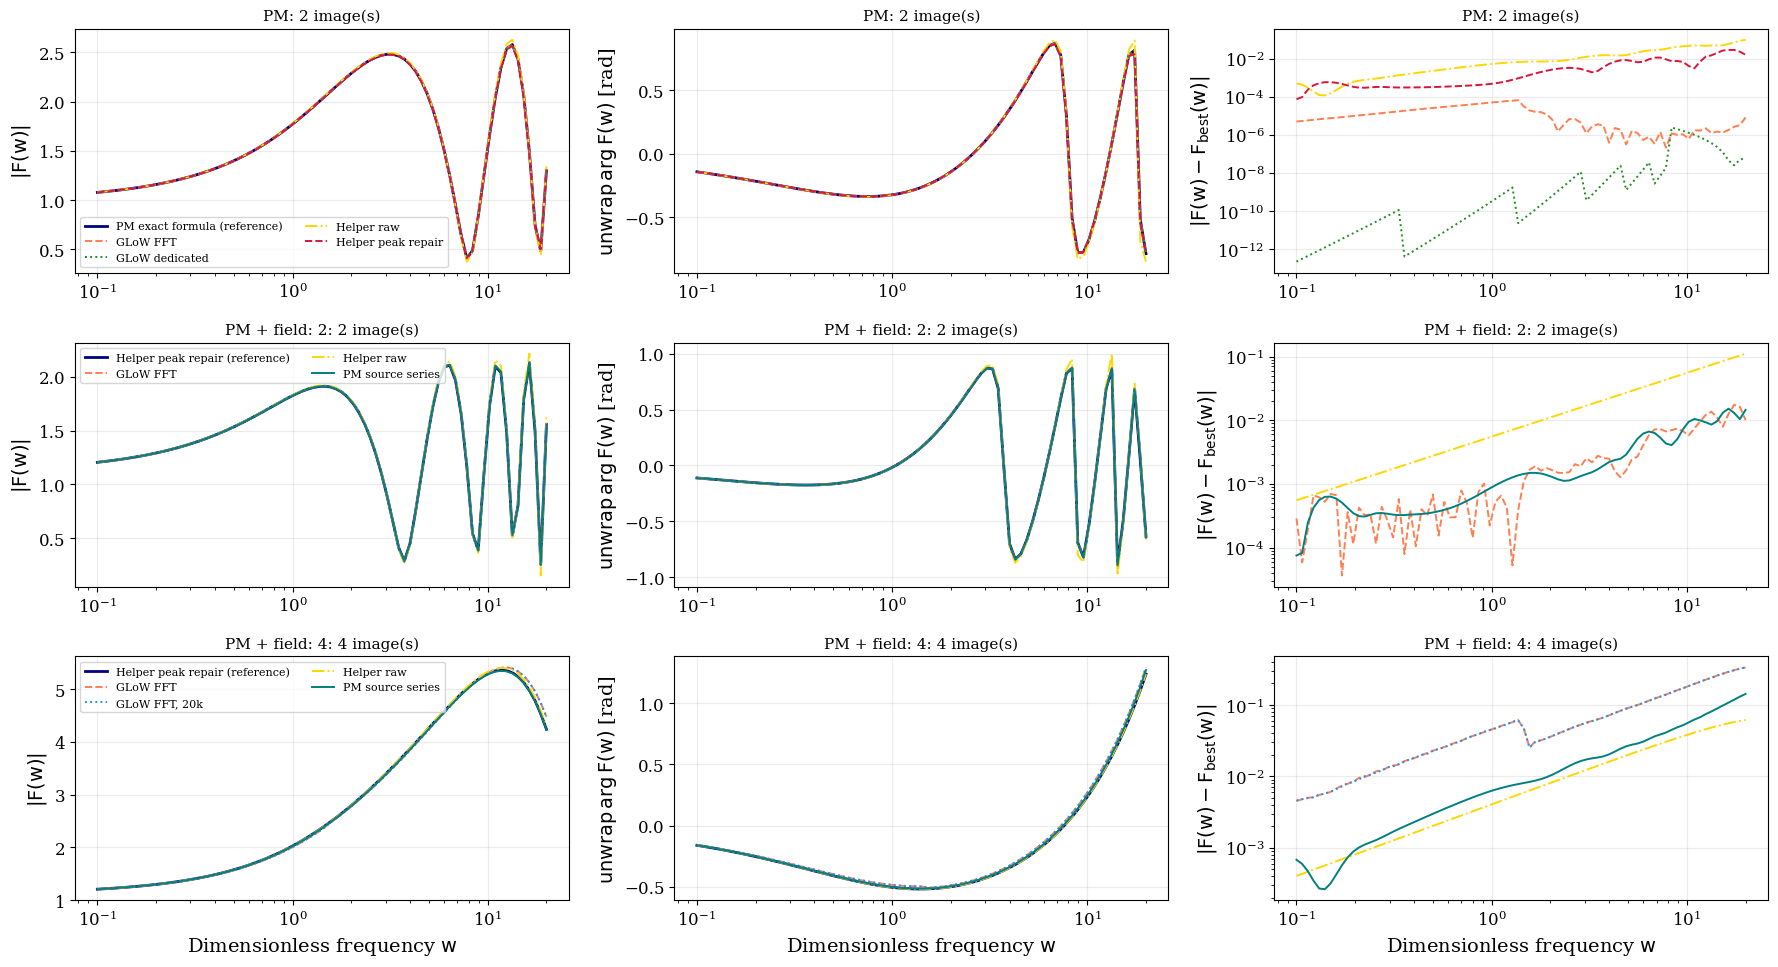

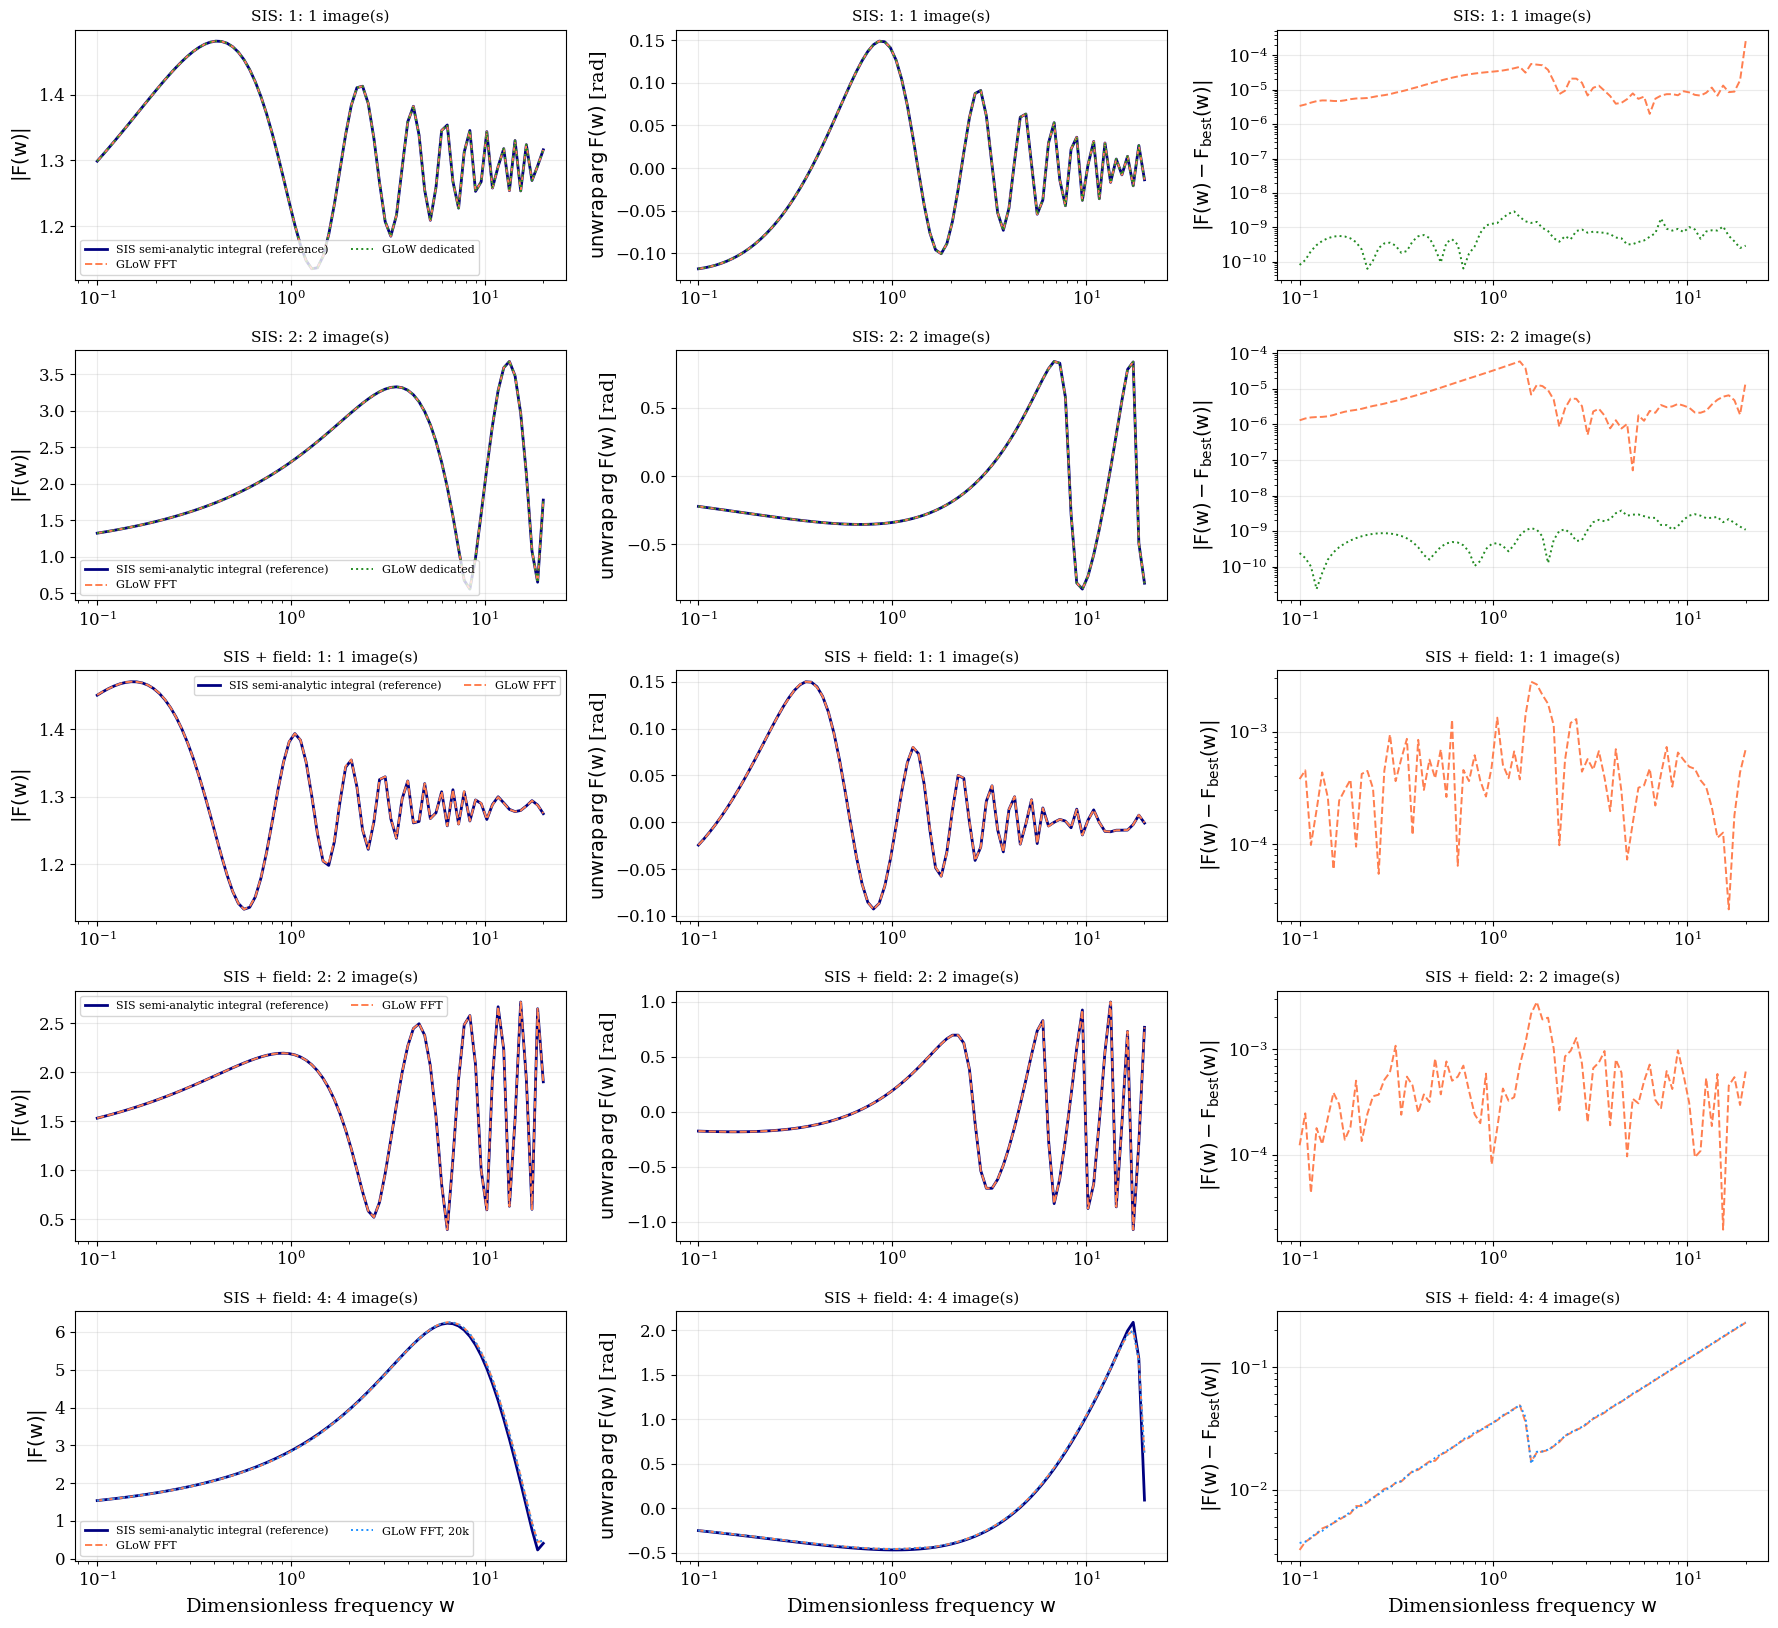

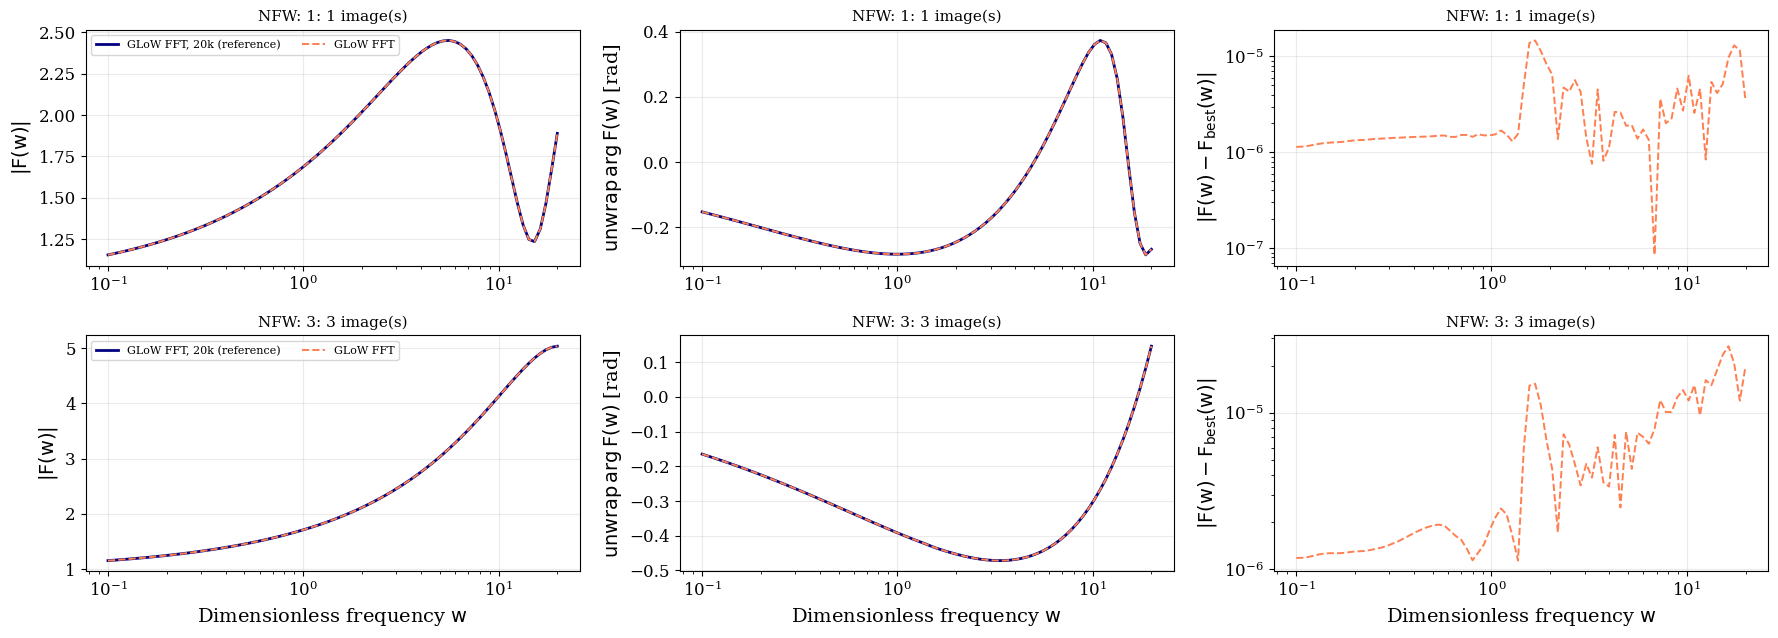

In [7]:
def plot_case_group(names, filename):
    """Show complex amplification and residuals for the original notebook cases."""
    fig, axes = plt.subplots(len(names), 3, figsize=(18, 3.3*len(names)), squeeze=False)
    method_styles = {'GLoW FFT': ('coral', '--'), 'GLoW FFT, 20k': ('dodgerblue', ':'),
                     'GLoW dedicated': ('forestgreen', ':'), 'Helper raw': ('gold', '-.'),
                     'Helper peak repair': ('crimson', '--'), 'PM source series': ('teal', '-')}
    for row, name in enumerate(names):
        curves = case_curves(name)
        best_name = choose_case_reference(curves)
        best = curves[best_name]
        axes[row, 0].plot(W, abs(best), color='navy', label=f'{best_name} (reference)')
        axes[row, 1].plot(W, np.unwrap(np.angle(best)), color='navy')
        for method_name, result in curves.items():
            if method_name == best_name:
                continue
            color, style = method_styles.get(method_name, ('teal', '--'))
            axes[row, 0].plot(W, abs(result), color=color, ls=style, lw=1.4,
                              label=method_name)
            axes[row, 1].plot(W, np.unwrap(np.angle(result)), color=color,
                              ls=style, lw=1.4)
            axes[row, 2].plot(W, np.maximum(abs(result-best), 1e-14), color=color,
                              ls=style, lw=1.4)
        axes[row, 0].set_ylabel(r'$|F(w)|$')
        axes[row, 1].set_ylabel(r'$\mathrm{unwrap}\,\arg F(w)$ [rad]')
        axes[row, 2].set_ylabel(r'$|F(w)-F_{\rm best}(w)|$')
        axes[row, 2].set_yscale('log')
        for ax in axes[row]:
            ax.set_xscale('log')
            ax.grid(alpha=.25)
            ax.set_title(f'{name}: {image_counts[name]} image(s)', fontsize=11)
        axes[row, 0].legend(fontsize=8, ncol=2)
    for ax in axes[-1]:
        ax.set_xlabel(r'Dimensionless frequency $w$')
    fig.tight_layout()
    fig.savefig(filename, dpi=200)
    plt.show()

plot_case_group([x['id'] for x in CASES if x['model'].startswith('PM')], 'full_model_pm.jpg')
plot_case_group([x['id'] for x in CASES if x['model'].startswith('SIS')], 'full_model_sis.jpg')
plot_case_group([x['id'] for x in CASES if x['model'] == 'NFW'], 'full_model_nfw.jpg')


![PM amplitude, phase, and residual](full_model_pm.jpg)

![SIS amplitude, phase, and residual](full_model_sis.jpg)

![NFW numerical grid comparison](full_model_nfw.jpg)


## Published isolated-lens checks

[Takahashi & Nakamura, Figs. 2–3](https://arxiv.org/abs/astro-ph/0305055) plot PM and SIS
amplification for $y=0.1,0.3,1,3$ over roughly $10^{-3}\leq w\leq100$.
[GLoW, Figs. 8–9](https://arxiv.org/abs/2409.04606) compare its numerical and dedicated
expressions at $y=0.3$ and $1.2$. [FIONA, Fig. 10](https://arxiv.org/abs/2603.12333)
compares GLoW and FIONA for an isolated SIS at $y=0.25$. The numerical checks below use
those published parameter choices. Published figure images are retained for visual context.

**Takahashi & Nakamura, Figs. 2–3**

![Published PM and SIS curves](attachment:Takahashi and Nakamura 2003, Figs. 2 and 3.jpg)
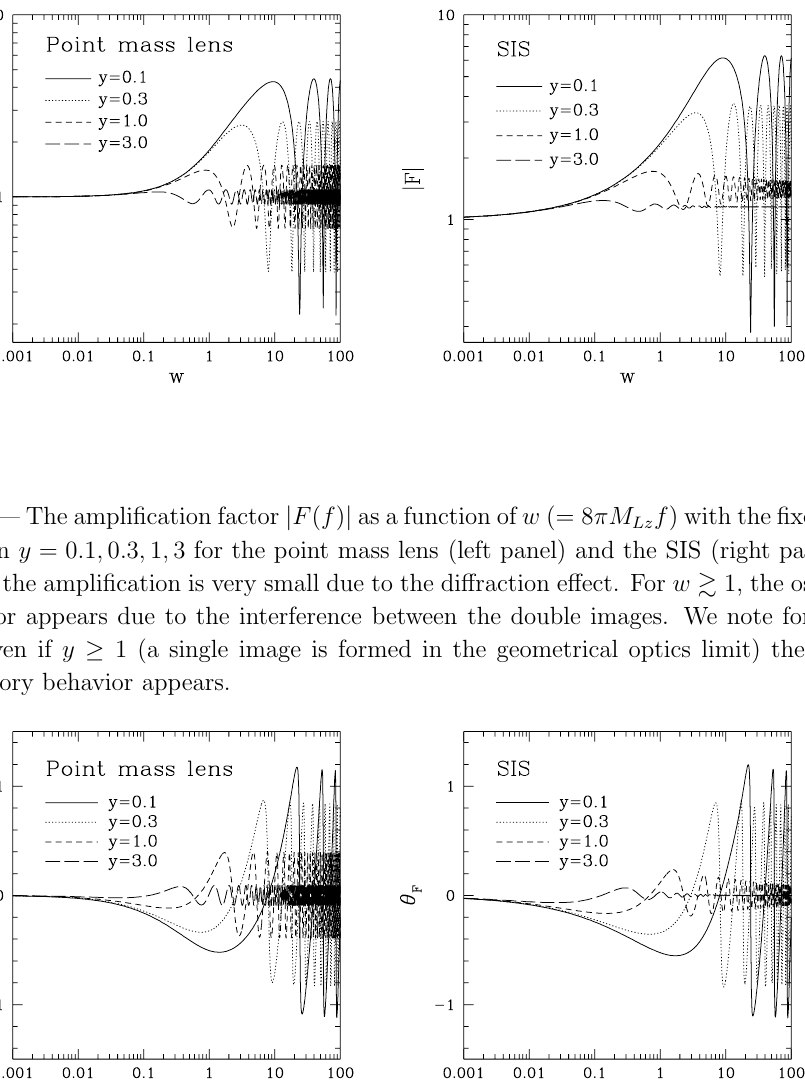

**FIONA, Fig. 10**

![Published SIS comparison](attachment:FIONA 2026, Fig. 10.jpg)
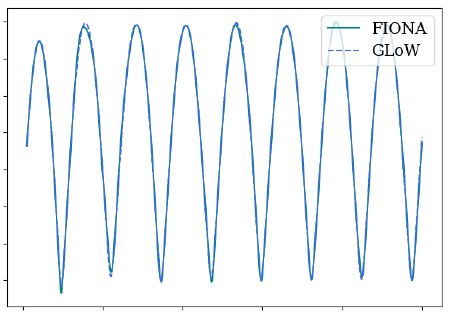

In [9]:
PAPER_W = np.r_[np.geomspace(1e-3, 1, 50), np.linspace(1.01, 100, 100)]
PAPER_SAMPLE = PAPER_W[::3]
paper_rows = []
fig, axes = plt.subplots(2, 1, figsize=(11.5, 9), sharex=True)
for row, profile in enumerate(('PM', 'SIS')):
    for y in (.1, .3, 1., 3.):
        if profile == 'PM':
            fast = freq_domain_c.Fw_AnalyticPointLens_C(y, {'parallel': False})(PAPER_W)
            exact = point_mass_formula(PAPER_SAMPLE, y)
            sampled_fast = freq_domain_c.Fw_AnalyticPointLens_C(y, {'parallel': False})(PAPER_SAMPLE)
        else:
            fast = freq_domain_c.Fw_SemiAnalyticSIS_C(y, {'parallel': False})(PAPER_W)
            exact = SISAngular(y, 0., n_angle=1536 if y >= 3 else 768)(PAPER_SAMPLE)
            sampled_fast = freq_domain_c.Fw_SemiAnalyticSIS_C(y, {'parallel': False})(PAPER_SAMPLE)
        axes[row].plot(PAPER_W, abs(fast), label=f'$y={y:g}$')
        axes[row].plot(PAPER_SAMPLE, abs(exact), 'k.', ms=2)
        difference = abs(sampled_fast-exact)
        paper_rows.append({'profile': profile, 'y': y, 'median complex error': np.median(difference),
                           'maximum complex error': np.max(difference)})
    axes[row].set_xscale('log')
    axes[row].set_ylabel(r'$|F(w)|$')
    axes[row].set_title(f'Isolated {profile}: published source choices')
    axes[row].grid(alpha=.25)
    axes[row].legend(ncol=4, fontsize=10)
axes[-1].set_xlabel(r'Dimensionless frequency $w$')
fig.tight_layout()
fig.savefig('published_isolated_checks.jpg', dpi=200)
plt.show()

FIONA_W = np.linspace(.1, 100, 300)
fiona_formula = SISAngular(.25, 0., n_angle=768)(FIONA_W)
fiona_glow = freq_domain_c.Fw_SemiAnalyticSIS_C(.25, {'parallel': False})(FIONA_W)
paper_rows.append({'profile': 'SIS (FIONA)', 'y': .25,
                   'median complex error': np.median(abs(fiona_glow-fiona_formula)),
                   'maximum complex error': np.max(abs(fiona_glow-fiona_formula))})
paper_accuracy = pd.DataFrame(paper_rows)
display(paper_accuracy)

GSL ERROR: cannot reach tolerance because of roundoff error [qawo.c:435]
GSL ERROR: exceeded limit of trigonometric table [qawo.c:453]
GSL ERROR: cannot reach tolerance because of roundoff error [qawo.c:435]
GSL ERROR: exceeded limit of trigonometric table [qawo.c:453]
GSL ERROR: cannot reach tolerance because of roundoff error [qawo.c:435]
GSL ERROR: exceeded limit of trigonometric table [qawo.c:453]
GSL ERROR: cannot reach tolerance because of roundoff error [qawo.c:435]
GSL ERROR: exceeded limit of trigonometric table [qawo.c:453]
GSL ERROR: cannot reach tolerance because of roundoff error [qawo.c:435]
GSL ERROR: exceeded limit of trigonometric table [qawo.c:453]
GSL ERROR: cannot reach tolerance because of roundoff error [qawo.c:435]
GSL ERROR: exceeded limit of trigonometric table [qawo.c:453]
GSL ERROR: cannot reach tolerance because of roundoff error [qawo.c:435]
GSL ERROR: exceeded limit of trigonometric table [qawo.c:453]
GSL ERROR: cannot reach tolerance because of roundoff e

/tmp/ipykernel_24276/684300382.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,profile,y,median complex error,maximum complex error
0,PM,0.10,4.062432e-11,5.978592e-08
1,PM,0.30,2.468404e-10,2.731901e-06
2,PM,1.00,8.716280e-10,2.631803e-06
3,PM,3.00,4.963157e-10,1.336356e-06
4,SIS,0.10,1.204821e-09,4.130231e-09
5,SIS,0.30,1.086231e-09,3.070653e-09
6,SIS,1.00,2.277282e-09,5.543843e-09
7,SIS,3.00,1.258222e-09,7.363536e-08
8,SIS (FIONA),0.25,1.349037e-09,5.532288e-09


![Published isolated-lens comparisons](published_isolated_checks.jpg)

## Computational cost from the saved 10-choice benchmark

Each table cell is the mean wall time over 10 parameter choices for the same 1,024 frequencies as the final accuracy comparison. **First use** includes preparation plus one frequency grid. **Repeated use** evaluates another grid after preparation. Both helper variants pay the full contour preparation cost when used alone. These timings are hardware and settings dependent.


In [2]:
import json
from pathlib import Path

# Read the measured times; no lens or frequency calculation is repeated here.
cost_results = json.loads(Path('report_benchmark_results.json').read_text())
method_names = ('Analytical', 'Series', 'Helper raw', 'Helper repaired',
                'GLoW dedicated', 'GLoW 5k', 'GLoW 20k')
for heading, field in (('First use', 'new_s'), ('Repeated use', 'repeat_s')):
    rows = []
    for group in cost_results:
        row = {'Lens and regime': group['label']}
        for method in method_names:
            records = [sample['records'].get(method) for sample in group['samples']]
            row[method] = (np.mean([record[field] for record in records])
                           if all(record is not None and record['success'] for record in records)
                           else np.nan)
        rows.append(row)
    print(heading, '[seconds for 1,024 frequencies]')
    display(pd.DataFrame(rows).set_index('Lens and regime').round(4))

First use [seconds for 1,024 frequencies]


,Analytical,Series,Helper raw,Helper repaired,GLoW dedicated,GLoW 5k,GLoW 20k
Lens and regime,,,,,,,
"PM, 2 images",0.3316,NaN,2.3025,2.3025,0.0005,0.0177,0.0612
"PM + field, 2 images",NaN,26.5769,2.5336,2.5336,NaN,0.5198,2.0371
"PM + field, 4 images",NaN,23.2915,2.6029,2.6029,NaN,0.6486,2.5939
"SIS, 1 image",0.1602,NaN,NaN,NaN,0.0270,0.0098,0.0287
"SIS, 2 images",0.1529,NaN,NaN,NaN,0.0043,0.0101,0.0295
"SIS + field, 1 image",0.1631,NaN,NaN,NaN,NaN,0.3107,1.2340
"SIS + field, 2 images",0.1532,NaN,NaN,NaN,NaN,0.3462,1.3738
"SIS + field, 4 images",0.1471,NaN,NaN,NaN,NaN,0.4452,1.8197
"NFW, 1 image",NaN,NaN,NaN,NaN,NaN,0.0200,0.0679


Repeated use [seconds for 1,024 frequencies]


,Analytical,Series,Helper raw,Helper repaired,GLoW dedicated,GLoW 5k,GLoW 20k
Lens and regime,,,,,,,
"PM, 2 images",0.3316,NaN,0.0001,0.0000,0.0003,0.0012,0.0011
"PM + field, 2 images",NaN,24.0499,0.0001,0.0001,NaN,0.0010,0.0011
"PM + field, 4 images",NaN,20.7314,0.0001,0.0001,NaN,0.0013,0.0013
"SIS, 1 image",0.1191,NaN,NaN,NaN,0.0268,0.0009,0.0008
"SIS, 2 images",0.1137,NaN,NaN,NaN,0.0040,0.0012,0.0013
"SIS + field, 1 image",0.1234,NaN,NaN,NaN,NaN,0.0009,0.0009
"SIS + field, 2 images",0.1139,NaN,NaN,NaN,NaN,0.0013,0.0013
"SIS + field, 4 images",0.1079,NaN,NaN,NaN,NaN,0.0013,0.0013
"NFW, 1 image",NaN,NaN,NaN,NaN,NaN,0.0009,0.0009


### First use: preparation plus 1,024 frequencies

| Lens and image regime | PM exact / SIS semi-analytic | Series | Helper raw | Helper repaired | GLoW dedicated | GLoW 5k | GLoW 20k |
| --- | --- | --- | --- | --- | --- | --- | --- |
| PM, 2 images | 332 ms | — | 2.3 s | 2.3 s | 0.465 ms | 17.7 ms | 61.2 ms |
| PM + field, 2 images | — | 26.6 s | 2.53 s | 2.53 s | — | 520 ms | 2.04 s |
| PM + field, 4 images | — | 23.3 s | 2.6 s | 2.6 s | — | 649 ms | 2.59 s |
| SIS, 1 image | 160 ms | — | — | — | 27 ms | 9.82 ms | 28.7 ms |
| SIS, 2 images | 153 ms | — | — | — | 4.27 ms | 10.1 ms | 29.5 ms |
| SIS + field, 1 image | 163 ms | — | — | — | — | 311 ms | 1.23 s |
| SIS + field, 2 images | 153 ms | — | — | — | — | 346 ms | 1.37 s |
| SIS + field, 4 images | 147 ms | — | — | — | — | 445 ms | 1.82 s |
| NFW, 1 image | — | — | — | — | — | 20 ms | 67.9 ms |
| NFW, 3 images | — | — | — | — | — | 21 ms | 69.2 ms |

### Repeated use: another 1,024 frequencies after preparation

| Lens and image regime | PM exact / SIS semi-analytic | Series | Helper raw | Helper repaired | GLoW dedicated | GLoW 5k | GLoW 20k |
| --- | --- | --- | --- | --- | --- | --- | --- |
| PM, 2 images | 332 ms | — | 0.0703 ms | 0.0379 ms | 0.253 ms | 1.2 ms | 1.14 ms |
| PM + field, 2 images | — | 24 s | 0.089 ms | 0.0667 ms | — | 1.03 ms | 1.06 ms |
| PM + field, 4 images | — | 20.7 s | 0.0751 ms | 0.065 ms | — | 1.26 ms | 1.31 ms |
| SIS, 1 image | 119 ms | — | — | — | 26.8 ms | 0.864 ms | 0.818 ms |
| SIS, 2 images | 114 ms | — | — | — | 3.97 ms | 1.17 ms | 1.25 ms |
| SIS + field, 1 image | 123 ms | — | — | — | — | 0.863 ms | 0.864 ms |
| SIS + field, 2 images | 114 ms | — | — | — | — | 1.28 ms | 1.32 ms |
| SIS + field, 4 images | 108 ms | — | — | — | — | 1.32 ms | 1.33 ms |
| NFW, 1 image | — | — | — | — | — | 0.88 ms | 0.895 ms |
| NFW, 3 images | — | — | — | — | — | 1.11 ms | 1.1 ms |


The [standalone report](test_glow_report.md) includes the implementation and accuracy tables alongside these cost tables.


## Reading the results

The exact PM expression and the independent SIS semi-analytic angular integral test both amplitude and
phase. The full PM source series is additionally checked against direct diffraction
integration. GLoW's dedicated isolated-lens routines and general FFT have different
performance and precision. The helper applies only to PM lenses, including the complete
quadratic external field. Its peak repair is assessed in both two- and four-image regimes.

NFW has no independent wave-optics formula in this notebook, so its 5k–20k comparison is
strictly a numerical grid check. Increasing GLoW's time-grid length alone need not reduce
the four-image error; contour integration and tail treatment also matter. All results here
are for positive-parity external fields and the stated frequency band.

## Standalone report

The [10-choice report](test_glow_report.md) is built from [saved benchmark results](report_benchmark_results.json) by [report_benchmark.py](report_benchmark.py). The report uses the same reference ranking as the section below. Running this notebook does not overwrite the report.


## Rotation consistency for the full shear matrix

A physical configuration is unchanged if the source and external shear axes are rotated
together. The helper's principal-axis case is rotated by $0.37$ radians below, giving both
$\gamma_1$ and $\gamma_2$ nonzero. The difference between the two independently sampled
helper contours measures its finite lens-plane grid error. This checks that the helper's
general shear components and two source coordinates represent the same four-parameter model.

In [13]:
case = CASE_BY_ID['PM + field: 2']
rotation = .37
c, s = np.cos(rotation), np.sin(rotation)
rotated_source = (c*case['y1']-s*case['y2'], s*case['y1']+c*case['y2'])
rotated_lens = SLML(k=case['kappa'], g1=case['gamma']*np.cos(2*rotation),
                    g2=case['gamma']*np.sin(2*rotation), mratio=1.,
                    y1=rotated_source[0], y2=rotated_source[1])
delays, response = Ftilde_contour(
    rotated_lens, HELPER_T_MAX, HELPER_DT, dx1=HELPER_DX, dx2=HELPER_DX)
uniform_time = np.linspace(0, HELPER_T_MAX, HELPER_N_TIME)
raw = interp1d(delays, response, fill_value='extrapolate')(uniform_time)
repaired = ReconstructPeak(rotated_lens, uniform_time, raw).get_peak_reconstructed_Ft()
rotated_frequencies, rotated_amplification = ampFac(uniform_time, repaired)
in_band = rotated_frequencies < 30
rotated_values = CubicSpline(
    rotated_frequencies[in_band], rotated_amplification[in_band])(W)
rotation_difference = abs(rotated_values-values[case['id']]['Helper peak repair'])
rotation_median = np.median(rotation_difference)
rotation_maximum = np.max(rotation_difference)
print('Original and rotated image counts:', image_counts[case['id']], len(rotated_lens.img))
print('Rotation median and maximum complex difference:', rotation_median, rotation_maximum)
assert len(rotated_lens.img) == image_counts[case['id']]
assert rotation_median < .005 and rotation_maximum < .02

report_path = Path('test_glow_report.md')
report = report_path.read_text()
rotation_section = (f'## Rotation consistency\n\n'
                    f'A simultaneous rotation of the two-image PM source and shear by '
                    f'{rotation} radians gives nonzero $\\gamma_1$ and $\\gamma_2$ in the helper. '
                    f'Its peak-repaired contour result differs from the unrotated calculation '
                    f'by a median {rotation_median:.4g} and maximum {rotation_maximum:.4g} '
                    f'in complex amplification over the same 80 frequencies. The residual '
                    f'is from finite spatial sampling.\n\n')
report_path.write_text(report.replace('## Scope', rotation_section + '## Scope'))

Original and rotated image counts: 2 2
Rotation median and maximum complex difference: 0.0006468810067793986 0.004527561676261545


9481

## Ten-choice benchmark with repaired-helper priority

The data below are the **same saved complex amplification values and timings** used in the report: 10 parameter choices for each image regime and 1,024 logarithmically spaced frequencies from $w=0.1$ to $20$. No lens calculation is repeated.

`Helper repaired` is the `helper_corrected` calculation. The reference order is: **independent PM formula or SIS semi-analytic integral → repaired helper → GLoW 20k → raw helper → GLoW dedicated → GLoW 5k → PM series**. For PM plus field, this selects the repaired helper. The ranking is a comparison convention; agreement with it is not proof of absolute accuracy. The SIS integral still needs numerical angular quadrature.


In [2]:
import json
from pathlib import Path

# Load the saved F(w) values and choose the reference without rerunning any lens calculation.
benchmark_results = json.loads(Path('report_benchmark_results.json').read_text())
benchmark_w = np.geomspace(0.1, 20, 1024)
reference_order = ('Analytical', 'Helper repaired', 'GLoW 20k', 'Helper raw',
                   'GLoW dedicated', 'GLoW 5k', 'Series')
method_names = ('Analytical', 'Series', 'Helper raw', 'Helper repaired',
                'GLoW dedicated', 'GLoW 5k', 'GLoW 20k')

for group in benchmark_results:
    for sample in group['samples']:
        F = {name: np.array(value['real']) + 1j*np.array(value['imag'])
             for name, value in sample['values'].items()}
        reference_name = next(name for name in reference_order if name in F)
        sample['best'] = reference_name
        sample['errors'] = {name: float(np.sum(np.abs(value-F[reference_name])))
                            for name, value in F.items()}

# Each table entry is the mean of the 10 discrete sums over the same 1,024 frequencies.
accuracy_rows = []
for group in benchmark_results:
    row = {'Lens and regime': group['label']}
    for name in method_names:
        errors = [sample['errors'].get(name) for sample in group['samples']]
        row[name] = np.mean(errors) if all(value is not None for value in errors) else np.nan
    accuracy_rows.append(row)
benchmark_accuracy = pd.DataFrame(accuracy_rows).set_index('Lens and regime')
display(benchmark_accuracy.round(3))

,Analytical,Series,Helper raw,Helper repaired,GLoW dedicated,GLoW 5k,GLoW 20k
Lens and regime,,,,,,,
"PM, 2 images",0.0,NaN,10.312,6.678,0.0,0.013,0.013
"PM + field, 2 images",NaN,5.466,11.965,0.000,NaN,5.573,5.554
"PM + field, 4 images",NaN,16.167,16.458,0.000,NaN,57.123,57.098
"SIS, 1 image",0.0,NaN,NaN,NaN,0.0,0.014,0.012
"SIS, 2 images",0.0,NaN,NaN,NaN,0.0,0.016,0.016
"SIS + field, 1 image",0.0,NaN,NaN,NaN,NaN,0.560,0.696
"SIS + field, 2 images",0.0,NaN,NaN,NaN,NaN,0.606,0.828
"SIS + field, 4 images",0.0,NaN,NaN,NaN,NaN,51.596,52.146
"NFW, 1 image",NaN,NaN,NaN,NaN,NaN,0.003,0.000


### Mean summed complex residual

Each entry is $\langle\sum_{i=1}^{1024}|F(w_i)-F_{\rm best}(w_i)|\rangle$ over the 10 choices. A zero marks the selected reference. A dash means the method does not implement that lens model.

| Lens and image regime | PM exact / SIS semi-analytic | Series | Helper raw | Helper repaired | GLoW dedicated | GLoW 5k | GLoW 20k |
| --- | --- | --- | --- | --- | --- | --- | --- |
| PM, 2 images | 0 | — | 10.3 | 6.68 | 0.000133 | 0.0126 | 0.0127 |
| PM + field, 2 images | — | 5.47 | 12 | 0 | — | 5.57 | 5.55 |
| PM + field, 4 images | — | 16.2 | 16.5 | 0 | — | 57.1 | 57.1 |
| SIS, 1 image | 0 | — | — | — | 6.89e-07 | 0.0135 | 0.0123 |
| SIS, 2 images | 0 | — | — | — | 1.14e-06 | 0.0156 | 0.0157 |
| SIS + field, 1 image | 0 | — | — | — | — | 0.56 | 0.696 |
| SIS + field, 2 images | 0 | — | — | — | — | 0.606 | 0.828 |
| SIS + field, 4 images | 0 | — | — | — | — | 51.6 | 52.1 |
| NFW, 1 image | — | — | — | — | — | 0.00325 | 0 |
| NFW, 3 images | — | — | — | — | — | 0.00604 | 0 |


In [3]:
from report_benchmark import plot_row

# Only redraw the figures from the saved arrays; F(w) and timing data stay unchanged.
for number, group in enumerate(benchmark_results, start=1):
    plot_row(group['label'], group['model'], group['samples'], number)
print('Saved 10 comparison figures in report_figures/.')

Install LaTeX, dvipng, and txfonts separately for LaTeX plot labels.


Saved 10 comparison figures in report_figures/.


### Amplification and residuals

Each row shows one of the 10 parameter choices. The panels give $|F(w)|$, unwrapped $\arg F(w)$, and $|F(w)-F_{\rm best}(w)|$. The reference curve has zero residual and is omitted from the logarithmic residual panel.

**PM, 2 images**

![PM, 2 images amplification and residual](report_figures/case_01.jpg)

**PM + field, 2 images**

![PM + field, 2 images amplification and residual](report_figures/case_02.jpg)

**PM + field, 4 images**

![PM + field, 4 images amplification and residual](report_figures/case_03.jpg)

**SIS, 1 image**

![SIS, 1 image amplification and residual](report_figures/case_04.jpg)

**SIS, 2 images**

![SIS, 2 images amplification and residual](report_figures/case_05.jpg)

**SIS + field, 1 image**

![SIS + field, 1 image amplification and residual](report_figures/case_06.jpg)

**SIS + field, 2 images**

![SIS + field, 2 images amplification and residual](report_figures/case_07.jpg)

**SIS + field, 4 images**

![SIS + field, 4 images amplification and residual](report_figures/case_08.jpg)

**NFW, 1 image**

![NFW, 1 image amplification and residual](report_figures/case_09.jpg)

**NFW, 3 images**

![NFW, 3 images amplification and residual](report_figures/case_10.jpg)
